# Customer Canvas
### Where behaviour becomes insight.

**Customer Analytics | SQL | Python | Pandas**

This project analyses customer purchasing behaviour, customer segmentation, repeat purchases, and retention using the UCI Online Retail dataset.

**Objectives**
- Clean and prepare transactional data.
- Analyse sales and purchasing patterns.
- Segment customers using RFM analysis.
- Evaluate customer retention using cohort analysis.
- Develop actionable business recommendations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders available here:")
print(os.listdir())

Current working directory:
C:\Users\HP\Desktop\MCA\projects\Customer Canvas\data

Files and folders available here:
['.ipynb_checkpoints', 'customer_analysis.ipynb', 'Online Retail.xlsx', 'requirements.txt']


In [5]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.00,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.00,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom


In [6]:
# Inspect dataset structure and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [7]:
# Check missing values in each column
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing_values.sort_values(
    by="Missing Percentage",
    ascending=False
))

,Missing Count,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27
InvoiceNo,0,0.00
StockCode,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [8]:
# Check duplicate records
print("Total duplicate rows:", df.duplicated().sum())

# Inspect transaction quantities and prices
display(df[["Quantity", "UnitPrice"]].describe())

Total duplicate rows: 5268


,Quantity,UnitPrice
count,541909.00,541909.00
mean,9.55,4.61
std,218.08,96.76
min,-80995.00,-11062.06
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,80995.00,38970.00


In [9]:
# Inspect transaction identifiers
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Unique customers:", df["CustomerID"].nunique())
print("Unique countries:", df["Country"].nunique())

# Check date range
print("First transaction:", df["InvoiceDate"].min())
print("Last transaction:", df["InvoiceDate"].max())

Unique invoices: 25900
Unique products: 4070
Unique customers: 4372
Unique countries: 38
First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00


In [10]:
# Identify cancelled invoices
cancelled_mask = (
    df["InvoiceNo"].astype(str).str.startswith("C")
)

print("Cancelled transaction rows:", cancelled_mask.sum())
print(
    "Unique cancelled invoices:",
    df.loc[cancelled_mask, "InvoiceNo"].nunique()
)

display(df.loc[cancelled_mask].head())

Cancelled transaction rows: 9288
Unique cancelled invoices: 3836


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.00,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.00,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.00,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.00,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.00,United Kingdom


In [11]:
print("Rows with negative quantity:", (df["Quantity"] < 0).sum())
print("Rows with zero quantity:", (df["Quantity"] == 0).sum())

print("Rows with negative unit price:", (df["UnitPrice"] < 0).sum())
print("Rows with zero unit price:", (df["UnitPrice"] == 0).sum())

print("\nExamples of negative quantities:")
display(df.loc[df["Quantity"] < 0].head(10))

print("\nExamples of non-positive unit prices:")
display(df.loc[df["UnitPrice"] <= 0].head(10))

Rows with negative quantity: 10624
Rows with zero quantity: 0
Rows with negative unit price: 2
Rows with zero unit price: 2515

Examples of negative quantities:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.00,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.00,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.00,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.00,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.00,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.00,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.00,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.00,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.00,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.00,United Kingdom



Examples of non-positive unit prices:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.00,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.00,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.00,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.00,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.00,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.00,NaN,United Kingdom


In [12]:
print("Rows with missing descriptions:", df["Description"].isnull().sum())

display(df.loc[df["Description"].isnull()].head(10))

Rows with missing descriptions: 1454


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.00,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.00,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.00,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.00,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.00,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.00,NaN,United Kingdom


In [13]:
# Preserve the original dataset
df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing exact duplicates:", len(df_clean))
print("Duplicate rows removed:", len(df) - len(df_clean))

Original rows: 541909
Rows after removing exact duplicates: 536641
Duplicate rows removed: 5268


In [14]:
# Identify cancelled invoices
cancelled_mask = (
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
)

# Keep valid positive sales transactions
sales_mask = (
    ~cancelled_mask
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] > 0)
)

sales_data = df_clean.loc[sales_mask].copy()

# Calculate line-level sales value
sales_data["TotalSales"] = (
    sales_data["Quantity"] * sales_data["UnitPrice"]
)

print("Rows available for standard sales analysis:", len(sales_data))
print("Total sales value (£):", round(sales_data["TotalSales"].sum(), 2))
print("Missing CustomerIDs retained:", sales_data["CustomerID"].isna().sum())

display(sales_data.head())

Rows available for standard sales analysis: 524878
Total sales value (£): 10642110.8
Missing CustomerIDs retained: 132186


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.00,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.00,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom,20.34


In [15]:
# Keep only transactions with identifiable customers
customer_data = sales_data.dropna(subset=["CustomerID"]).copy()

# CustomerID represents an identifier, not a numeric measurement
customer_data["CustomerID"] = (
    customer_data["CustomerID"].astype(int).astype(str)
)

print("Rows available for customer analysis:", len(customer_data))
print("Unique customers:", customer_data["CustomerID"].nunique())
print("Missing CustomerIDs:", customer_data["CustomerID"].isna().sum())

display(customer_data.head())

Rows available for customer analysis: 392692
Unique customers: 4338
Missing CustomerIDs: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [16]:
print("Sales Data Validation")
print("-" * 35)
print("Duplicate rows:", sales_data.duplicated().sum())
print("Non-positive quantities:", (sales_data["Quantity"] <= 0).sum())
print("Non-positive unit prices:", (sales_data["UnitPrice"] <= 0).sum())
print("Cancelled invoices:", sales_data["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Missing customer IDs:", sales_data["CustomerID"].isna().sum())

print("\nCustomer Data Validation")
print("-" * 35)
print("Duplicate rows:", customer_data.duplicated().sum())
print("Missing customer IDs:", customer_data["CustomerID"].isna().sum())
print("Non-positive sales values:", (customer_data["TotalSales"] <= 0).sum())

assert sales_data["Quantity"].gt(0).all()
assert sales_data["UnitPrice"].gt(0).all()
assert not sales_data["InvoiceNo"].astype(str).str.startswith("C").any()
assert customer_data["CustomerID"].notna().all()
assert not customer_data.duplicated().any()

print("\nAll validation checks passed!")

Sales Data Validation
-----------------------------------
Duplicate rows: 0
Non-positive quantities: 0
Non-positive unit prices: 0
Cancelled invoices: 0
Missing customer IDs: 132186

Customer Data Validation
-----------------------------------
Duplicate rows: 0
Missing customer IDs: 0
Non-positive sales values: 0

All validation checks passed!


In [17]:
total_sales = sales_data["TotalSales"].sum()
total_invoices = sales_data["InvoiceNo"].nunique()
total_customers = customer_data["CustomerID"].nunique()

invoice_sales = sales_data.groupby("InvoiceNo")["TotalSales"].sum()
average_order_value = invoice_sales.mean()

print(f"Total Sales: £{total_sales:,.2f}")
print(f"Unique Invoices: {total_invoices:,}")
print(f"Identifiable Customers: {total_customers:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

Total Sales: £10,642,110.80
Unique Invoices: 19,960
Identifiable Customers: 4,338
Average Order Value: £533.17


,Total Sales (£)
InvoiceDate,
2010-12-01,821452.73
2011-01-01,689811.61
2011-02-01,522545.56
2011-03-01,716215.26
2011-04-01,536968.49
2011-05-01,769296.61
2011-06-01,760547.01
2011-07-01,718076.12
2011-08-01,757841.38


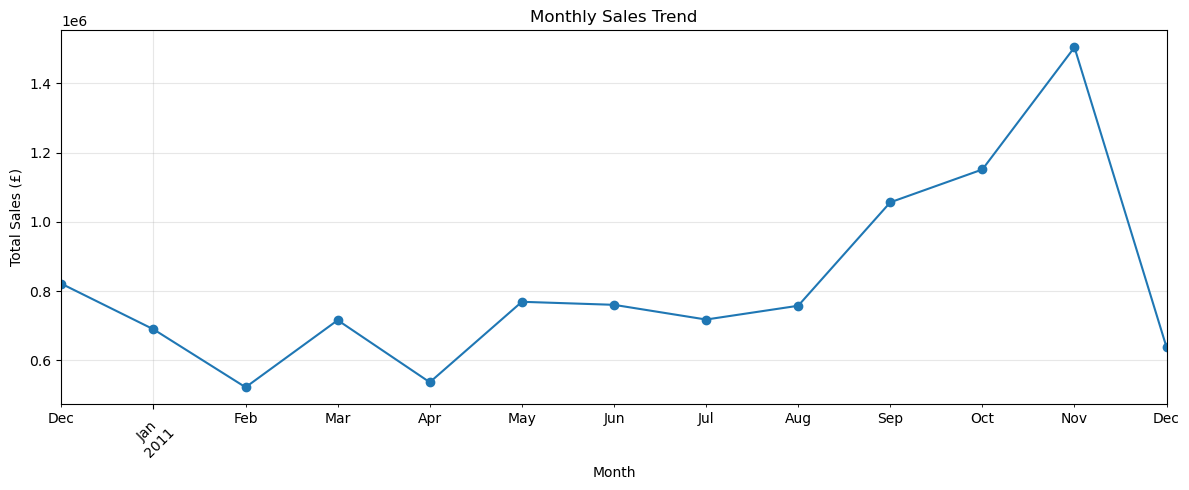

In [18]:
# Create a monthly sales summary
monthly_sales = (
    sales_data
    .set_index("InvoiceDate")
    .resample("MS")["TotalSales"]
    .sum()
)

display(monthly_sales.to_frame(name="Total Sales (£)"))

# Plot monthly sales
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
best_month = monthly_sales.idxmax()
lowest_month = monthly_sales.idxmin()

print("Highest-sales month:", best_month.strftime("%B %Y"))
print(f"Sales in highest-sales month: £{monthly_sales.max():,.2f}")

print("\nLowest-sales month:", lowest_month.strftime("%B %Y"))
print(f"Sales in lowest-sales month: £{monthly_sales.min():,.2f}")

Highest-sales month: November 2011
Sales in highest-sales month: £1,503,866.78

Lowest-sales month: February 2011
Sales in lowest-sales month: £522,545.56


In [20]:
customer_summary = (
    customer_data
    .groupby("CustomerID")
    .agg(
        TotalSpent=("TotalSales", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        TotalItems=("Quantity", "sum"),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    )
)

customer_summary["AverageOrderValue"] = (
    customer_summary["TotalSpent"] /
    customer_summary["TotalOrders"]
)

display(
    customer_summary
    .sort_values("TotalSpent", ascending=False)
    .head(10)
)

,TotalSpent,TotalOrders,TotalItems,FirstPurchase,LastPurchase,AverageOrderValue
CustomerID,,,,,,
14646,280206.02,73,196915,2010-12-20 10:09:00,2011-12-08 12:12:00,3838.44
18102,259657.30,60,64124,2010-12-07 16:42:00,2011-12-09 11:50:00,4327.62
17450,194390.79,46,69973,2010-12-07 09:23:00,2011-12-01 13:29:00,4225.89
16446,168472.50,2,80997,2011-05-18 09:52:00,2011-12-09 09:15:00,84236.25
14911,143711.17,201,80240,2010-12-01 14:05:00,2011-12-08 15:54:00,714.98
12415,124914.53,21,77374,2011-01-06 11:12:00,2011-11-15 14:22:00,5948.31
14156,117210.08,55,57768,2010-12-03 11:48:00,2011-11-30 10:54:00,2131.09
17511,91062.38,31,64549,2010-12-01 10:19:00,2011-12-07 10:12:00,2937.50
16029,80850.84,63,40108,2010-12-01 09:57:00,2011-11-01 10:27:00,1283.35


In [21]:
print("Total identifiable customers:", len(customer_summary))

print(
    "Average customer spending (£):",
    round(customer_summary["TotalSpent"].mean(), 2)
)

print(
    "Median customer spending (£):",
    round(customer_summary["TotalSpent"].median(), 2)
)

print(
    "Average orders per customer:",
    round(customer_summary["TotalOrders"].mean(), 2)
)

print(
    "Customers with multiple orders:",
    (customer_summary["TotalOrders"] > 1).sum()
)

print(
    "Repeat-customer percentage:",
    round(
        (customer_summary["TotalOrders"] > 1).mean() * 100,
        2
    ),
    "%"
)

Total identifiable customers: 4338
Average customer spending (£): 2048.69
Median customer spending (£): 668.57
Average orders per customer: 4.27
Customers with multiple orders: 2845
Repeat-customer percentage: 65.58 %


In [22]:
# Use the day after the last transaction as the analysis date
analysis_date = customer_data["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = (
    customer_data
    .groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", lambda x: (analysis_date - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("TotalSales", "sum")
    )
)

display(rfm.head(10))

,Recency,Frequency,Monetary
CustomerID,,,
12346,325,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,18,1,1757.55
12350,310,1,334.40
12352,36,8,2506.04
12353,204,1,89.00
12354,232,1,1079.40
12355,214,1,459.40


In [23]:
# Score Recency: more recent customers receive higher scores
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Score Frequency: frequent customers receive higher scores
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Score Monetary: higher spenders receive higher scores
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine the three scores
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

display(rfm.head(10))

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346,325,1,77183.60,1,1,5,115
12347,2,7,4310.00,5,5,5,555
12348,75,4,1797.24,2,4,4,244
12349,18,1,1757.55,4,1,4,414
12350,310,1,334.40,1,1,2,112
12352,36,8,2506.04,3,5,5,355
12353,204,1,89.00,1,1,1,111
12354,232,1,1079.40,1,1,4,114
12355,214,1,459.40,1,1,2,112


In [24]:
display(
    rfm[
        [
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Score"
        ]
    ].head(10)
)

print("\nRFM score column type:", rfm["RFM_Score"].dtype)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346,325,1,77183.60,1,1,5,115
12347,2,7,4310.00,5,5,5,555
12348,75,4,1797.24,2,4,4,244
12349,18,1,1757.55,4,1,4,414
12350,310,1,334.40,1,1,2,112
12352,36,8,2506.04,3,5,5,355
12353,204,1,89.00,1,1,1,111
12354,232,1,1079.40,1,1,4,114
12355,214,1,459.40,1,1,2,112



RFM score column type: object


In [25]:
# Recreate the combined score explicitly
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(int).astype(str)
    + rfm["F_Score"].astype(int).astype(str)
    + rfm["M_Score"].astype(int).astype(str)
)

# Display only the required columns
display(
    rfm[
        [
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Score"
        ]
    ].head(10)
)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346,325,1,77183.60,1,1,5,115
12347,2,7,4310.00,5,5,5,555
12348,75,4,1797.24,2,4,4,244
12349,18,1,1757.55,4,1,4,414
12350,310,1,334.40,1,1,2,112
12352,36,8,2506.04,3,5,5,355
12353,204,1,89.00,1,1,1,111
12354,232,1,1079.40,1,1,4,114
12355,214,1,459.40,1,1,2,112


In [26]:
print("Column names:")
print(rfm.columns.tolist())

print("\nScore values for the first 5 customers:")
print(
    rfm[["R_Score", "F_Score", "M_Score", "RFM_Score"]]
    .head()
    .to_string()
)

Column names:
['Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score']

Score values for the first 5 customers:
            R_Score  F_Score  M_Score RFM_Score
CustomerID                                     
12346             1        1        5       115
12347             5        5        5       555
12348             2        4        4       244
12349             4        1        4       414
12350             1        1        2       112


In [27]:
def segment_customer(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    elif f >= 4 and m >= 3:
        return "Loyal Customers"
    elif r >= 4 and f >= 2:
        return "Potential Loyalists"
    elif r <= 2 and f >= 3 and m >= 3:
        return "At Risk - Valuable"
    elif r <= 2 and f <= 2:
        return "Hibernating"
    else:
        return "Others"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)

display(
    rfm[
        ["Recency", "Frequency", "Monetary",
         "R_Score", "F_Score", "M_Score", "RFM_Score", "Segment"]
    ].head(15)
)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
12346,325,1,77183.60,1,1,5,115,Hibernating
12347,2,7,4310.00,5,5,5,555,Champions
12348,75,4,1797.24,2,4,4,244,Loyal Customers
12349,18,1,1757.55,4,1,4,414,Others
12350,310,1,334.40,1,1,2,112,Hibernating
12352,36,8,2506.04,3,5,5,355,Loyal Customers
12353,204,1,89.00,1,1,1,111,Hibernating
12354,232,1,1079.40,1,1,4,114,Hibernating
12355,214,1,459.40,1,1,2,112,Hibernating


In [28]:
segment_summary = (
    rfm.groupby("Segment")
    .agg(
        CustomerCount=("Segment", "size"),
        AverageRecency=("Recency", "mean"),
        AverageFrequency=("Frequency", "mean"),
        AverageMonetary=("Monetary", "mean"),
        TotalRevenue=("Monetary", "sum")
    )
    .sort_values("CustomerCount", ascending=False)
)

segment_summary["CustomerPercentage"] = (
    segment_summary["CustomerCount"]
    / len(rfm) * 100
).round(2)

display(segment_summary.round(2))

,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary,TotalRevenue,CustomerPercentage
Segment,,,,,,
Hibernating,1072,216.47,1.10,488.07,523208.53,24.71
Champions,941,11.98,11.21,6101.93,5741913.58,21.69
Others,888,74.00,1.71,497.71,441963.44,20.47
Loyal Customers,709,70.43,5.20,1901.54,1348195.11,16.34
Potential Loyalists,514,16.06,2.12,996.48,512188.47,11.85
At Risk - Valuable,214,150.13,2.37,1494.11,319739.76,4.93


Segment
Hibernating            1072
Champions               941
Others                  888
Loyal Customers         709
Potential Loyalists     514
At Risk - Valuable      214
Name: count, dtype: int64


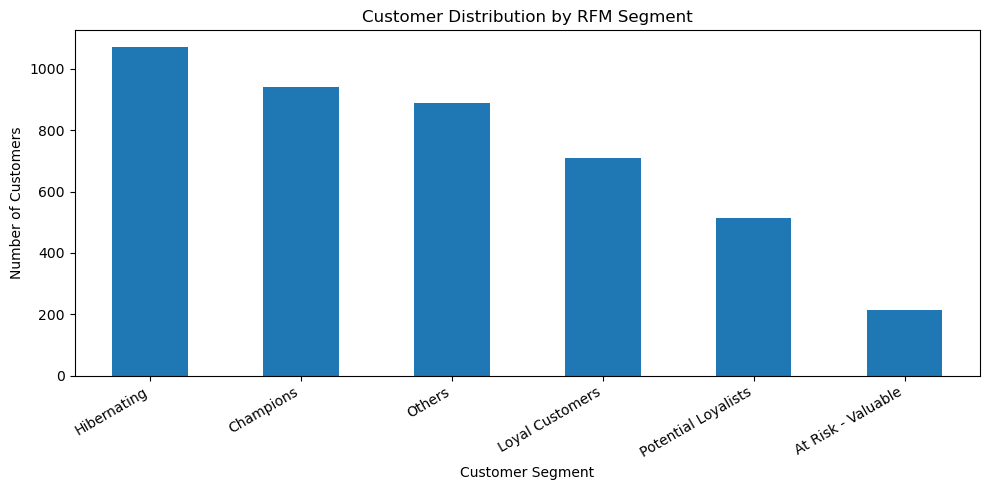

In [29]:
segment_counts = (
    rfm["Segment"]
    .value_counts()
    .sort_values(ascending=False)
)

print(segment_counts)

plt.figure(figsize=(10, 5))
segment_counts.plot(kind="bar")
plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [30]:
customer_summary["PurchaseType"] = np.where(
    customer_summary["TotalOrders"] == 1,
    "One-time Customer",
    "Repeat Customer"
)

purchase_summary = (
    customer_summary
    .groupby("PurchaseType")
    .agg(
        CustomerCount=("TotalOrders", "size"),
        AverageOrders=("TotalOrders", "mean"),
        AverageSpending=("TotalSpent", "mean"),
        TotalRevenue=("TotalSpent", "sum")
    )
)

purchase_summary["CustomerPercentage"] = (
    purchase_summary["CustomerCount"]
    / len(customer_summary) * 100
).round(2)

display(purchase_summary.round(2))

,CustomerCount,AverageOrders,AverageSpending,TotalRevenue,CustomerPercentage
PurchaseType,,,,,
One-time Customer,1493,1.00,411.25,613989.56,34.42
Repeat Customer,2845,5.99,2907.99,8273219.33,65.58


In [31]:
cohort_data = customer_data.copy()

# Identify each customer's first purchase month
cohort_data["InvoiceMonth"] = (
    cohort_data["InvoiceDate"].dt.to_period("M")
)

cohort_data["CohortMonth"] = (
    cohort_data.groupby("CustomerID")["InvoiceDate"]
    .transform("min")
    .dt.to_period("M")
)

# Calculate months since the customer's first purchase
cohort_data["CohortIndex"] = (
    (cohort_data["InvoiceMonth"].dt.year
     - cohort_data["CohortMonth"].dt.year) * 12
    + (cohort_data["InvoiceMonth"].dt.month
       - cohort_data["CohortMonth"].dt.month)
    + 1
)

display(
    cohort_data[
        ["CustomerID", "InvoiceDate", "InvoiceMonth",
         "CohortMonth", "CohortIndex"]
    ].head(10)
)

,CustomerID,InvoiceDate,InvoiceMonth,CohortMonth,CohortIndex
0,17850,2010-12-01 08:26:00,2010-12,2010-12,1
1,17850,2010-12-01 08:26:00,2010-12,2010-12,1
2,17850,2010-12-01 08:26:00,2010-12,2010-12,1
3,17850,2010-12-01 08:26:00,2010-12,2010-12,1
4,17850,2010-12-01 08:26:00,2010-12,2010-12,1
5,17850,2010-12-01 08:26:00,2010-12,2010-12,1
6,17850,2010-12-01 08:26:00,2010-12,2010-12,1
7,17850,2010-12-01 08:28:00,2010-12,2010-12,1
8,17850,2010-12-01 08:28:00,2010-12,2010-12,1
9,13047,2010-12-01 08:34:00,2010-12,2010-12,1


In [32]:
cohort_counts = (
    cohort_data
    .groupby(["CohortMonth", "CohortIndex"])["CustomerID"]
    .nunique()
    .unstack()
)

cohort_sizes = cohort_counts.iloc[:, 0]

retention = cohort_counts.divide(cohort_sizes, axis=0) * 100

display(retention.round(1))

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,100.00,36.60,32.30,38.40,36.30,39.80,36.30,34.90,35.40,39.50,37.40,50.30,26.60
2011-01,100.00,22.10,26.60,23.00,32.10,28.80,24.70,24.20,30.00,32.60,36.50,11.80,NaN
2011-02,100.00,18.70,18.70,28.40,27.10,24.70,25.30,27.90,24.70,30.50,6.80,NaN,NaN
2011-03,100.00,15.00,25.20,19.90,22.30,16.80,26.80,23.00,27.90,8.60,NaN,NaN,NaN
2011-04,100.00,21.30,20.30,21.00,19.70,22.70,21.70,26.00,7.30,NaN,NaN,NaN,NaN
2011-05,100.00,19.00,17.30,17.30,20.80,23.20,26.40,9.50,NaN,NaN,NaN,NaN,NaN
2011-06,100.00,17.40,15.70,26.40,23.10,33.50,9.50,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.00,18.10,20.70,22.30,27.10,11.20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.00,20.70,24.90,24.30,12.40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
customer_data.to_csv(
    "customer_canvas_cleaned.csv",
    index=False
)

print("CSV exported successfully!")
print("Rows exported:", len(customer_data))

CSV exported successfully!
Rows exported: 392692


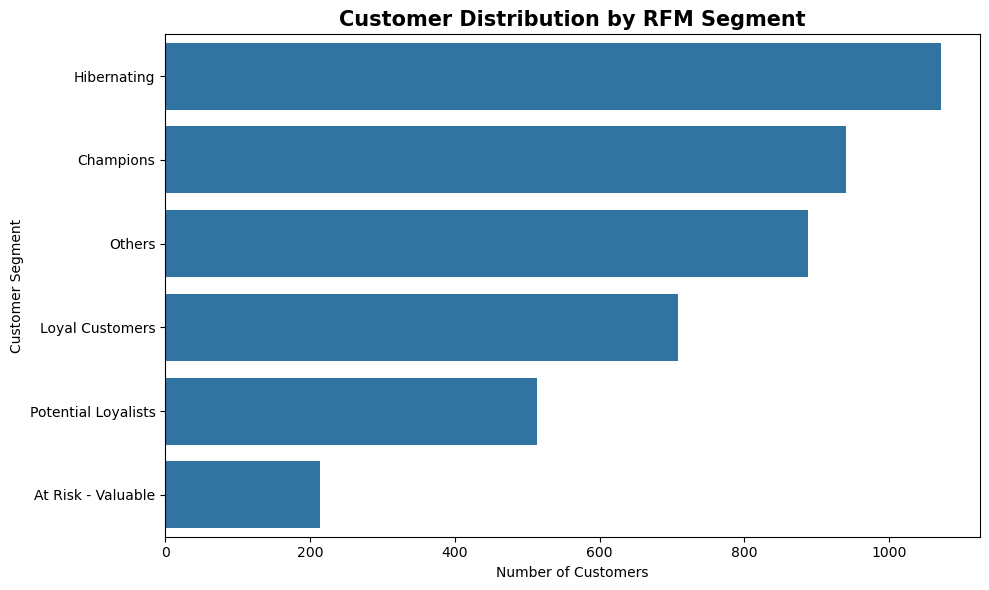

In [34]:

# 2. Customer Segment Distribution

segment_counts = (
    rfm["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="CustomerCount")
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=segment_counts,
    x="CustomerCount",
    y="Segment"
)

plt.title("Customer Distribution by RFM Segment",
          fontsize=15, fontweight="bold")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()


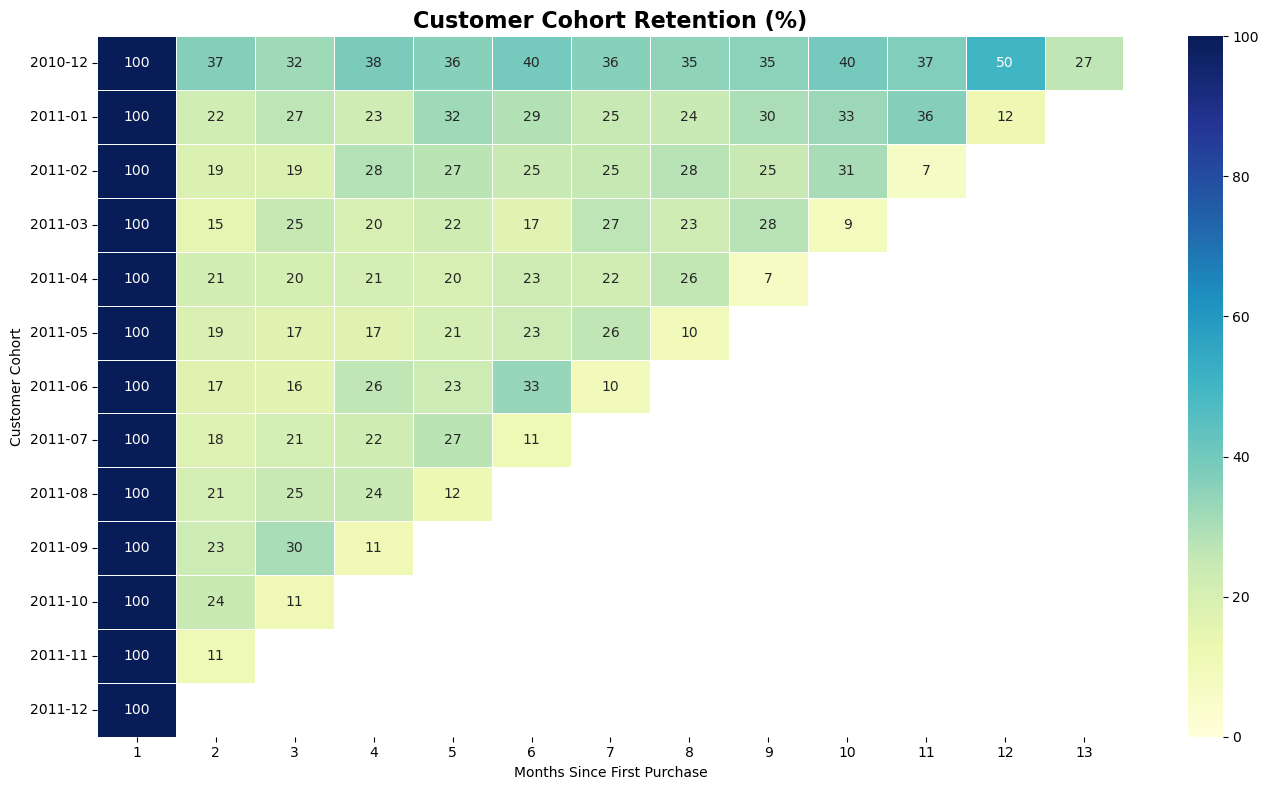

In [35]:

# 3. Cohort Retention Heatmap

retention_plot = retention.copy()
retention_plot.index = retention_plot.index.astype(str)

plt.figure(figsize=(14, 8))
sns.heatmap(
    retention_plot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5
)

plt.title("Customer Cohort Retention (%)",
          fontsize=16, fontweight="bold")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Cohort")
plt.tight_layout()
plt.show()


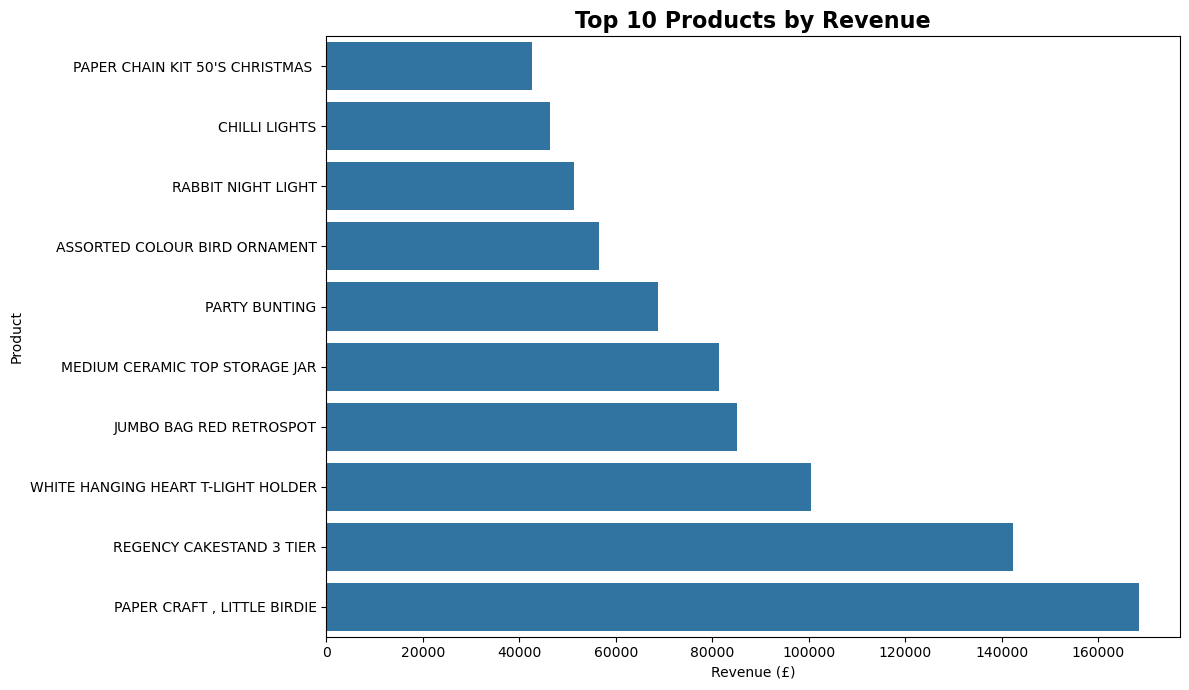

In [36]:

# 4. Top 10 Products by Revenue

product_revenue = (
    customer_data
    .groupby(["StockCode", "Description"], dropna=False)["TotalSales"]
    .sum()
    .reset_index()
    .dropna(subset=["StockCode", "Description"])
)

# Exclude generic service entries
product_revenue = product_revenue[
    ~product_revenue["StockCode"].astype(str).isin(["POST", "M"])
]

top_products = (
    product_revenue
    .sort_values("TotalSales", ascending=False)
    .head(10)
    .sort_values("TotalSales", ascending=True)
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_products,
    x="TotalSales",
    y="Description"
)

plt.title("Top 10 Products by Revenue",
          fontsize=16, fontweight="bold")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()
